### Gas Cylinder Evaluation

Standalone evaluation of each fine-tuned model on validation and test splits.

Datasets evaluated:
- `gas_bottles` — CylinDeRS, single class `gas_cylinder`
- `gas_cylinder` — Roboflow, 2 classes

For each dataset:
- Load `best.pt` from the matching training run
- Run `model.val()` on validation and test once each
- Print metrics directly (no CSV files)
- Show a few annotated test images inline
- Compare training-time and standalone-evaluation metrics in one table

Outputs: annotated prediction images under `results/gas_bottle_evaluation/annotated/`.

In [1]:
from pathlib import Path
import pandas as pd
import torch
import yaml
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

device = 0 if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

PyTorch: 2.14.1+cpu
CUDA available: False
Using device: cpu


### Inputs and outputs

**Input datasets:** `datasets/gas_bottles/`, `datasets/gas_cylinder/`.

**Input weights:** `results/gas_bottle_training/yolo11n_<dataset>/weights/best.pt`.

**Output:** `results/gas_bottle_evaluation/annotated/<dataset>/` — annotated test images only.

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATASETS_DIR = ROOT / "datasets"
RUNS_DIR = ROOT / "results" / "gas_bottle_training"
OUTPUT_DIR = ROOT / "results" / "gas_bottle_evaluation"
ANNOTATED_DIR = OUTPUT_DIR / "annotated"

ANNOTATED_DIR.mkdir(parents=True, exist_ok=True)

print(f"Datasets folder: {DATASETS_DIR.relative_to(ROOT)}")
print(f"Runs folder:     {RUNS_DIR.relative_to(ROOT)}")
print(f"Output folder:   {OUTPUT_DIR.relative_to(ROOT)}")

Datasets folder: datasets
Runs folder:     results\gas_bottle_training
Output folder:   results\gas_bottle_evaluation


### Verify available runs

List every dataset that has both a `data.yaml` and a `best.pt`.

In [3]:
DATASET_CANDIDATES = [
    "gas_bottles",
    "gas_cylinder",
]

def load_yaml(ds_dir):
    for name in ["data.yaml", "data_ultralytics.yaml"]:
        p = ds_dir / name
        if p.exists():
            return p, yaml.safe_load(p.read_text())
    return None, None

available = []

print("=" * 70)
print("AVAILABLE RUNS")
print("=" * 70)

for name in DATASET_CANDIDATES:
    ds = DATASETS_DIR / name
    run_dir = RUNS_DIR / f"yolo11n_{name}"
    best_pt = run_dir / "weights" / "best.pt"
    yaml_path, cfg = load_yaml(ds) if ds.exists() else (None, None)

    ok = ds.exists() and yaml_path is not None and best_pt.exists()
    print(f"{name:15s} dataset={ds.exists()}  yaml={yaml_path.name if yaml_path else None}  best.pt={best_pt.exists()}  ->  {'OK' if ok else 'SKIP'}")

    if ok:
        available.append({
            "name": name,
            "dataset_dir": ds,
            "yaml_path": yaml_path,
            "cfg": cfg,
            "run_dir": run_dir,
            "best_pt": best_pt,
        })

print(f"\nDatasets ready for evaluation: {[a['name'] for a in available]}")

AVAILABLE RUNS
gas_bottles     dataset=True  yaml=data.yaml  best.pt=True  ->  OK
gas_cylinder    dataset=True  yaml=data.yaml  best.pt=True  ->  OK

Datasets ready for evaluation: ['gas_bottles', 'gas_cylinder']


### Configuration

Same image size and batch size as the training runs, so metrics are comparable.

In [4]:
IMGSZ = 416
BATCH = 4
CONF = 0.25
MAX_ANNOTATED = 5

print(f"imgsz={IMGSZ}  batch={BATCH}  conf={CONF}  max_annotated={MAX_ANNOTATED}")

imgsz=416  batch=4  conf=0.25  max_annotated=5


### Validation and test evaluation

For each dataset, load `best.pt` and run `model.val()` on validation and test once each. Both metric rows are collected into `eval_rows`.

In [5]:
eval_rows = []

for entry in available:
    name = entry["name"]
    yaml_path = entry["yaml_path"]
    best_pt = entry["best_pt"]

    print("\n" + "=" * 60)
    print(f"Evaluating {name}  ->  {best_pt.relative_to(ROOT)}")
    print("=" * 60)

    model = YOLO(str(best_pt))

    for split in ["val", "test"]:
        metrics = model.val(
            data=str(yaml_path),
            split=split,
            imgsz=IMGSZ,
            batch=BATCH,
            device=device,
            project=str(OUTPUT_DIR),
            name=f"{name}_{split}",
            exist_ok=True,
            plots=True,
            verbose=False,
        )

        row = {
            "dataset": name,
            "split": split,
            "precision": float(metrics.box.mp),
            "recall": float(metrics.box.mr),
            "mAP50": float(metrics.box.map50),
            "mAP50-95": float(metrics.box.map),
        }
        eval_rows.append(row)

        print(f"{name:15s} {split:5s}  P={row['precision']:.4f}  R={row['recall']:.4f}  mAP50={row['mAP50']:.4f}  mAP50-95={row['mAP50-95']:.4f}")

df_eval = pd.DataFrame(eval_rows)


Evaluating gas_bottles  ->  results\gas_bottle_training\yolo11n_gas_bottles\weights\best.pt


Ultralytics 8.4.175  Python-3.11.9 torch-2.14.1+cpu CPU (AMD Ryzen 7 6800HS with Radeon Graphics)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.40.1 ms, read: 0.50.7 MB/s, size: 7.4 KB)
val: Scanning D:\BCS Files\Y3S1\AI Applications MBI38j\Labs\primagaz-yolo\datasets\gas_bottles\valid\labels.cache... 4808 images, 0 backgrounds, 54 corrupt: 100% ━━━━━━━━━━━━ 4862/4862  0.0s
val: D:\BCS Files\Y3S1\AI Applications MBI38j\Labs\primagaz-yolo\datasets\gas_bottles\valid\images\1_JPG_jpg.rf.0081d2a73451cf687fedfb424962b0d0.jpg: ignoring corrupt image/label: image size (10, 4) <10 pixels
val: D:\BCS Files\Y3S1\AI Applications MBI38j\Labs\primagaz-yolo\datasets\gas_bottles\valid\images\1_JPG_jpg.rf.0c8ad52afaf9da159ce4f7f034767351.jpg: ignoring corrupt image/label: image size (38, 9) <10 pixels
val: D:\BCS Files\Y3S1\AI Applications MBI38j\Labs\primagaz-yolo\datasets\gas_bottles\valid\images\1_JPG_jpg.rf.2c3cf3936cdc69162b94b

### Annotated examples

For each dataset, run the model on a handful of test images, save the annotated versions to disk, and display them inline.


gas_bottles
  -7-_png_jpg.rf.fa231b88048ce280d54562b688630131.jpg detections=1


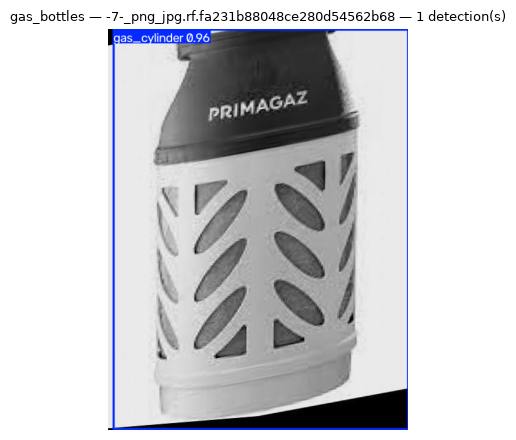

  -8-_png_jpg.rf.bbc5693caeb3b26e460574fd54071cdd.jpg detections=1


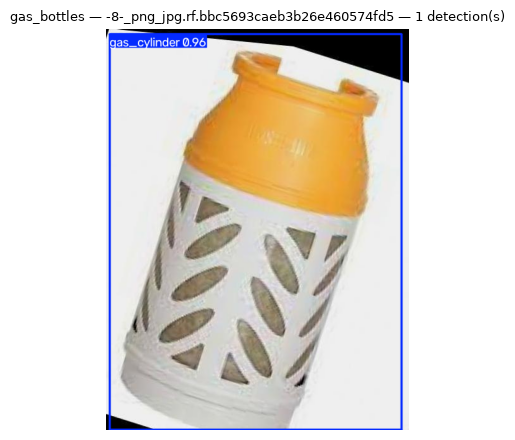

  101_jpg.rf.13308acea8d4e1d2f3594a50f500a907.jpg detections=1


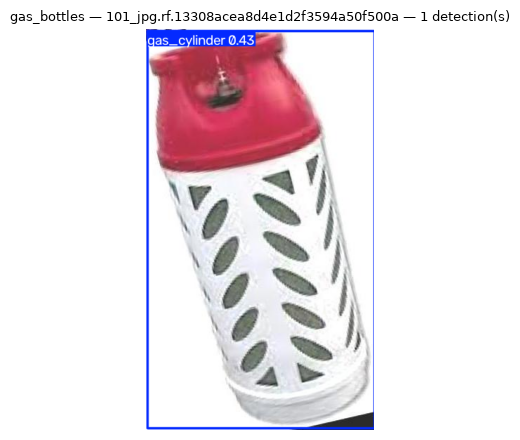

  101_jpg.rf.2d5ebb0da241cecb05647a1ea731eff0.jpg detections=0


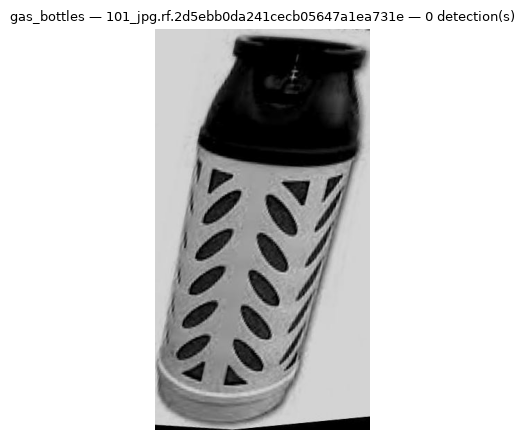

  105_jpg.rf.b6d4887972b91ec385e9de1d42ce3598.jpg detections=1


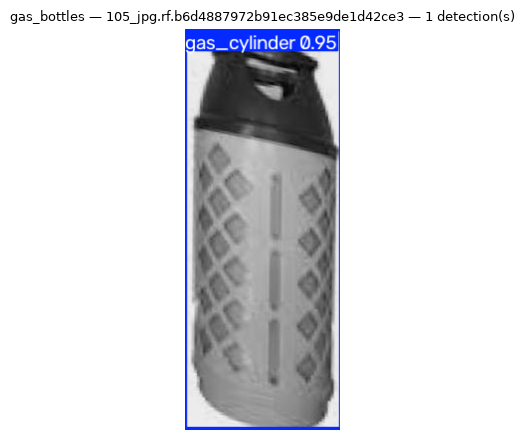


gas_cylinder
  20220823_121911_jpg.rf.a90e084d4fbf33d378aa68e5816a12bd.jpg detections=0


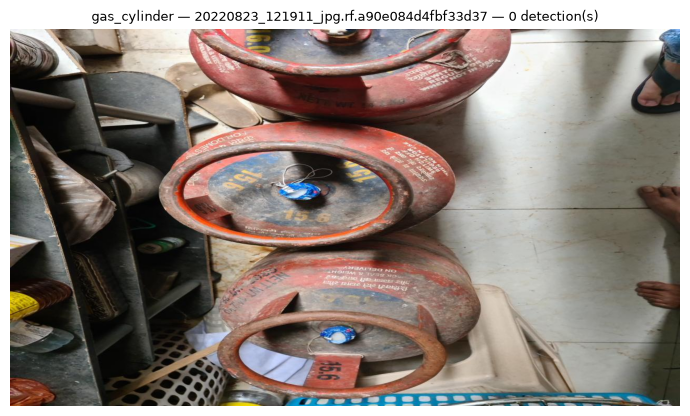

  20220823_122125_jpg.rf.85afd6bbd4116b28e6df3f29903837b6.jpg detections=1


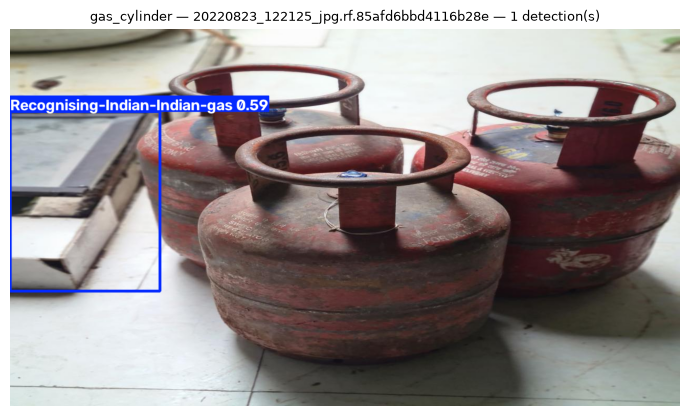

  20220823_122139_jpg.rf.b3ccc1ef1648721df2f694585d3a0e36.jpg detections=0


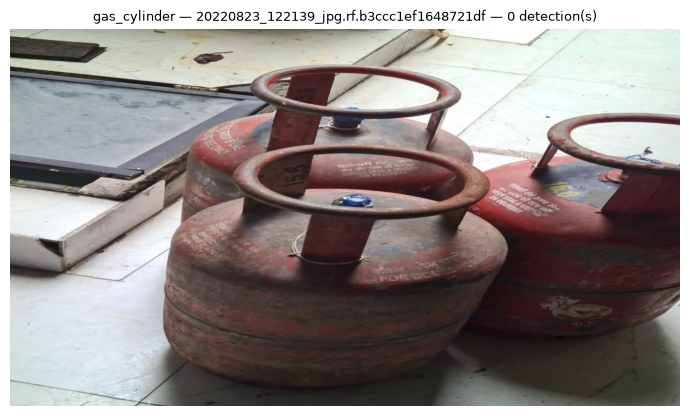

  20220823_122147_jpg.rf.39356cf3fa6c8bcf359410b20a836532.jpg detections=1


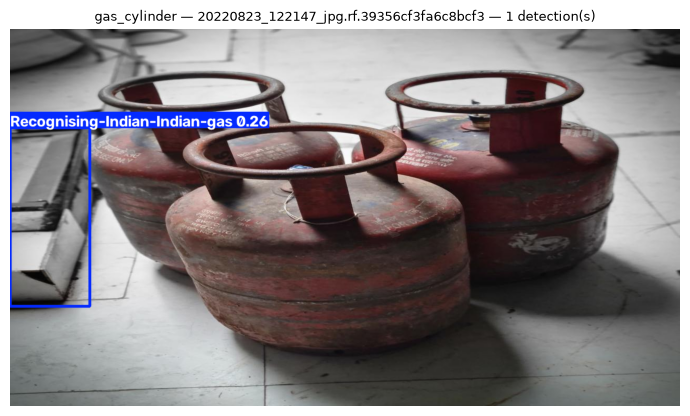

  20220823_122211_jpg.rf.92f3c206df5fddabe3a2c533b1e51e93.jpg detections=0


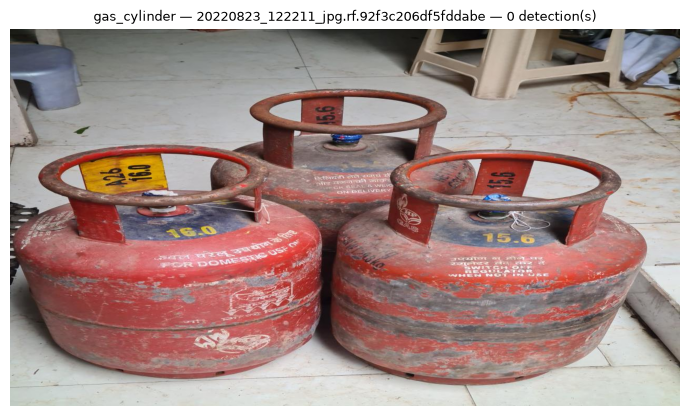

In [6]:
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for entry in available:
    name = entry["name"]
    ds = entry["dataset_dir"]
    best_pt = entry["best_pt"]

    test_images_dir = ds / "test" / "images"
    test_images = sorted(
        p for p in test_images_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTS
    ) if test_images_dir.exists() else []

    if not test_images:
        print(f"[skip] {name}: no test images")
        continue

    out_dir = ANNOTATED_DIR / name
    out_dir.mkdir(parents=True, exist_ok=True)

    model = YOLO(str(best_pt))
    sample = test_images[:MAX_ANNOTATED]

    print(f"\n{name}")

    for img_path in sample:
        res = model.predict(
            source=str(img_path),
            conf=CONF,
            imgsz=IMGSZ,
            device=device,
            verbose=False,
        )[0]

        annotated = res.plot()
        out_path = out_dir / f"pred_{img_path.stem}.jpg"
        cv2.imwrite(str(out_path), annotated)

        n = 0 if res.boxes is None else len(res.boxes)
        print(f"  {img_path.name:45s} detections={n}")

        rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.imshow(rgb)
        ax.axis("off")
        ax.set_title(f"{name} — {img_path.name[:40]} — {n} detection(s)", fontsize=9)
        plt.tight_layout()
        plt.show()

### Summary

In [7]:
pivot = df_eval.pivot_table(
    index="dataset",
    columns="split",
    values=["precision", "recall", "mAP50", "mAP50-95"],
    aggfunc="first",
)

print("=" * 80)
print("EVALUATION SUMMARY")
print("=" * 80)

for dataset_name in df_eval["dataset"].unique():
    sub = df_eval[df_eval["dataset"] == dataset_name][["split", "precision", "recall", "mAP50", "mAP50-95"]]
    print(f"\n{dataset_name}")
    print("-" * 80)
    print(sub.to_string(index=False))

print("\n" + "=" * 80)
print("INPUTS AND OUTPUTS")
print("=" * 80)
print(f"Input datasets:   {DATASETS_DIR.relative_to(ROOT)}/gas_bottles/, /gas_cylinder/")
print(f"Input weights:    {RUNS_DIR.relative_to(ROOT)}/yolo11n_<dataset>/weights/best.pt")
print(f"Annotated output: {ANNOTATED_DIR.relative_to(ROOT)}/<dataset>/")
print(f"Datasets evaluated: {df_eval['dataset'].unique().tolist()}")

EVALUATION SUMMARY

gas_bottles
--------------------------------------------------------------------------------
split  precision   recall    mAP50  mAP50-95
  val   0.968276 0.898710 0.977122  0.938166
 test   0.963415 0.902399 0.985904  0.946126

gas_cylinder
--------------------------------------------------------------------------------
split  precision   recall    mAP50  mAP50-95
  val   0.354692 0.276224 0.293840  0.180977
 test   0.194063 0.246881 0.177329  0.096033

INPUTS AND OUTPUTS
Input datasets:   datasets/gas_bottles/, /gas_cylinder/
Input weights:    results\gas_bottle_training/yolo11n_<dataset>/weights/best.pt
Annotated output: results\gas_bottle_evaluation\annotated/<dataset>/
Datasets evaluated: ['gas_bottles', 'gas_cylinder']
